In [1]:
#import libararies numpy, matplotlib, scikit learn, joblib.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

import joblib
from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
digits = load_digits()

images = digits.images
X = digits.data
y = digits.target

print("Total images:", len(images))
print("Original image dimensions:", images.shape)
print("Feature dimensions:", X.shape)
print("Target labels:", np.unique(y))

Total images: 1797
Original image dimensions: (1797, 8, 8)
Feature dimensions: (1797, 64)
Target labels: [0 1 2 3 4 5 6 7 8 9]


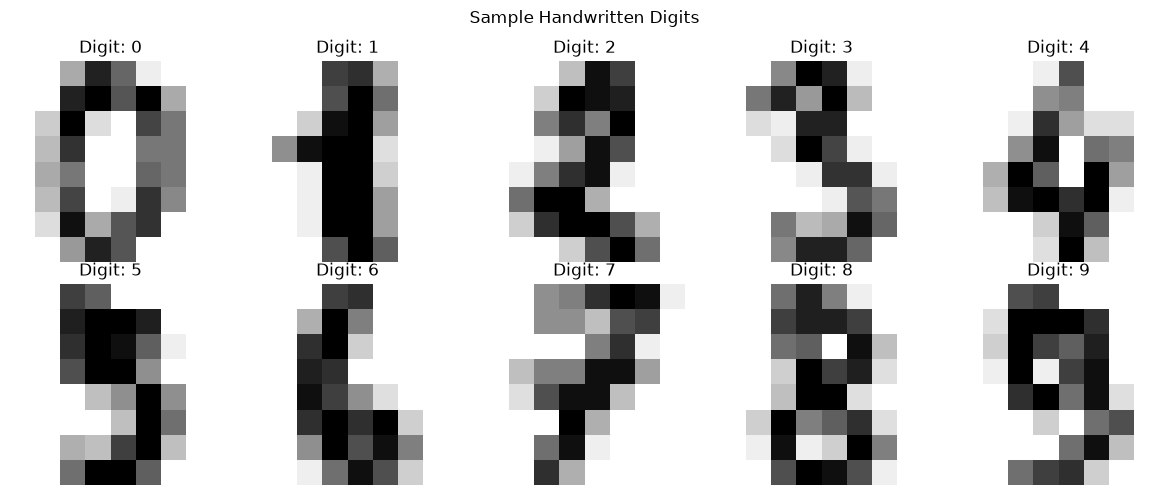

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray_r")
    ax.set_title(f"Digit: {y[i]}")
    ax.axis("off")

plt.suptitle("Sample Handwritten Digits")
plt.tight_layout()
plt.show()

In [4]:
print("Original image:")
print(images[0])

print("\nFlattened image:")
print(X[0])

print("\nActual digit label:", y[0])
print("Number of features:", len(X[0]))

Original image:
[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]

Flattened image:
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]

Actual digit label: 0
Number of features: 64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))

Training images: 1437
Testing images: 360
Training labels: 1437
Testing labels: 360


In [6]:
model = KNeighborsClassifier(n_neighbors=3)

model.fit(X_train, y_train)

print("KNN model training completed!")

KNN model training completed!


In [7]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("Correct predictions:", np.sum(y_pred == y_test))
print("Incorrect predictions:", np.sum(y_pred != y_test))
print("Total test images:", len(y_test))

Model Accuracy: 98.61%
Correct predictions: 355
Incorrect predictions: 5
Total test images: 360


In [8]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(10),
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      1.00      0.96        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       1.00      1.00      1.00        36
           8       0.97      0.91      0.94        35
           9       1.00      0.94      0.97        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



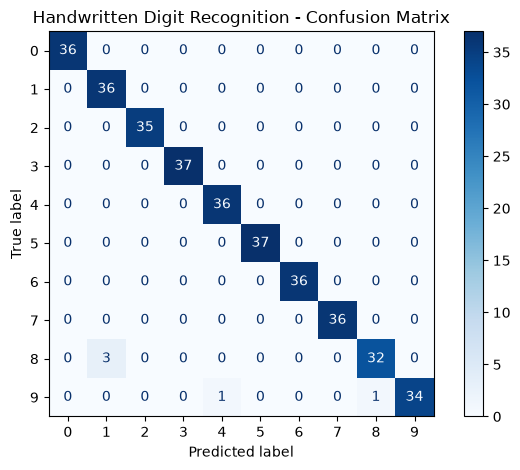

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=np.arange(10),
    cmap="Blues",
    values_format="d"
)

plt.title("Handwritten Digit Recognition - Confusion Matrix")
plt.tight_layout()
plt.show()

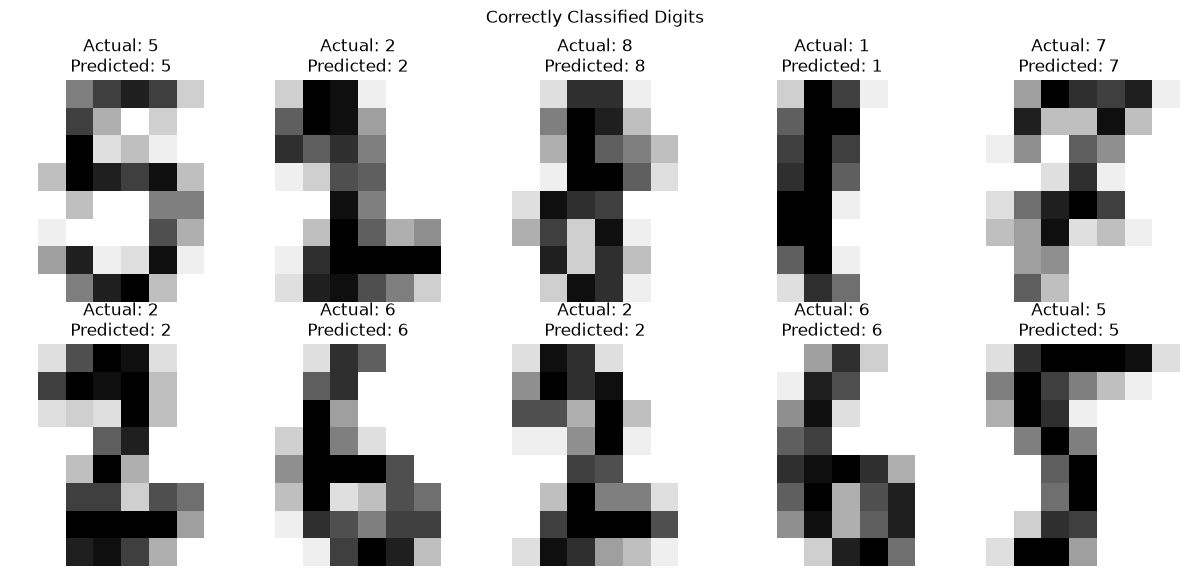

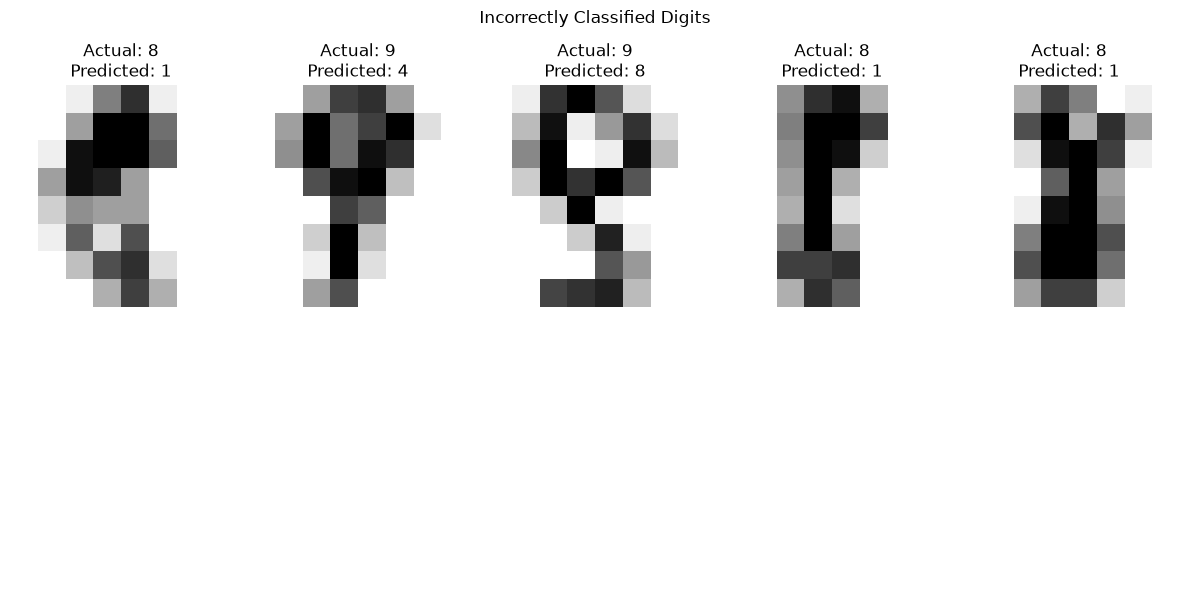

Correct examples: 355
Incorrect examples: 5


In [10]:
correct_indices = np.where(y_test == y_pred)[0]
incorrect_indices = np.where(y_test != y_pred)[0]


def display_gallery(indices, title, limit=10):
    count = min(len(indices), limit)

    if count == 0:
        print("No examples available:", title)
        return

    fig, axes = plt.subplots(2, 5, figsize=(12, 6))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for i, idx in enumerate(indices[:count]):
        axes[i].imshow(
            X_test[idx].reshape(8, 8),
            cmap="gray_r"
        )

        axes[i].set_title(
            f"Actual: {y_test[idx]}\n"
            f"Predicted: {y_pred[idx]}"
        )

        axes[i].axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


display_gallery(
    correct_indices,
    "Correctly Classified Digits"
)

display_gallery(
    incorrect_indices,
    "Incorrectly Classified Digits"
)

print("Correct examples:", len(correct_indices))
print("Incorrect examples:", len(incorrect_indices))

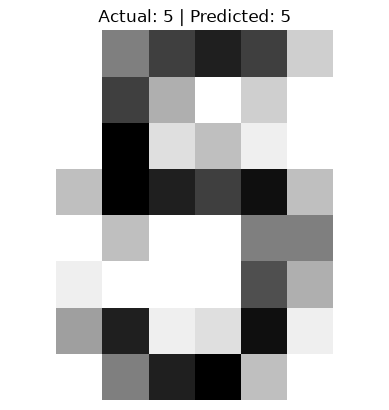

Actual digit: 5
Predicted digit: 5
Prediction correct: True


In [11]:
index = 0

sample = X_test[index].reshape(1, -1)
prediction = model.predict(sample)[0]
actual = y_test[index]

plt.imshow(X_test[index].reshape(8, 8), cmap="gray_r")
plt.title(f"Actual: {actual} | Predicted: {prediction}")
plt.axis("off")
plt.show()

print("Actual digit:", actual)
print("Predicted digit:", prediction)
print("Prediction correct:", actual == prediction)

In [12]:
Path("models").mkdir(exist_ok=True)

model_path = Path("models/knn_digits.joblib")

joblib.dump(model, model_path)

print("Model saved at:", model_path.resolve())

Model saved at: C:\Users\rajan\ML-010-Digit-Recognition\models\knn_digits.joblib


In [13]:
loaded_model = joblib.load(model_path)

new_predictions = loaded_model.predict(X_test[:5])

print("Reloaded model predictions:", new_predictions)
print("Actual labels:", y_test[:5])

assert np.array_equal(
    new_predictions,
    model.predict(X_test[:5])
)

print("Model reload test passed!")

Reloaded model predictions: [5 2 8 1 7]
Actual labels: [5 2 8 1 7]
Model reload test passed!


In [14]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=2000)
logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

print("KNN Accuracy:",
      f"{accuracy_score(y_test, y_pred) * 100:.2f}%")

print("Logistic Regression Accuracy:",
      f"{accuracy_score(y_test, logistic_pred) * 100:.2f}%")

KNN Accuracy: 98.61%
Logistic Regression Accuracy: 95.83%


# ML-010: Handwritten Digit Recognition

## Objective
To classify handwritten digits from 0 to 9 using a supervised machine learning algorithm.

## Dataset
- Source: scikit-learn built-in Digits dataset
- Total images: 1,797
- Image dimensions: 8 × 8 pixels
- Features per image: 64
- Classes: 0–9

## Methodology
1. Load the built-in dataset.
2. Inspect and visualize sample images.
3. Split data into 80% training and 20% testing.
4. Train a K-Nearest Neighbors classifier.
5. Evaluate the model using accuracy, precision, recall, F1-score and confusion matrix.
6. Visualize correct and incorrect predictions.
7. Save and reload the trained model.

## Results
- Algorithm: K-Nearest Neighbors
- Neighbors: 3
- Test samples: 360
- Test accuracy: [Insert actual notebook result]
- Common classification mistakes: [Describe observations from the confusion matrix]

## Conclusion
The project demonstrates how a machine learning classifier can recognize handwritten digits from numerical pixel features. Evaluation results help measure the model's performance and identify common classification errors. The project provides practical experience with data preprocessing, supervised learning, visualization and model evaluation.